# 05 · Multi-Echelon Stock Positioning

**Where in a supplier → DC → store chain should you hold inventory?** The
counterintuitive answer is *risk pooling*: consolidating safety stock at an upstream
node protects the whole network with **less total inventory** than holding a buffer at
every store, because independent demands aggregate with less proportional variability.

Holding the buffer at *N* stores needs `z·√L·Σσᵢ`; pooling it needs
`z·√L·√(Σσᵢ²)`, and `√(Σσᵢ²) ≤ Σσᵢ` always. The ratio is the **pooling factor**.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

from src.config import SETTINGS
from src.inventory.safety_stock import z_score
from src.network.multi_echelon import (
    centralized_safety_stock,
    compare_pooling,
    decentralized_safety_stock,
    pooling_factor,
)
from src.outputs import save_figure, save_json

plt.rcParams["figure.figsize"] = (7, 4)
lead_time = SETTINGS.safety_stock.lead_time
service_level = SETTINGS.safety_stock.service_level

## A distribution center serving six stores

Each store holds its own buffer today (decentralized). What if the DC pooled it?

In [2]:
sigmas = np.array([18.0, 22.0, 25.0, 30.0, 15.0, 20.0])
result = compare_pooling(sigmas, lead_time, service_level)
save_json({"sigmas": sigmas, "lead_time": lead_time, "service_level": service_level}, "05_inputs")
save_json(result, "05_pooling_result")

print(f"decentralized safety stock (every store): {result.decentralized:.1f}")
print(f"centralized safety stock (pooled at DC) : {result.centralized:.1f}")
print(f"inventory saved by pooling              : {result.savings:.1f}")
print(f"pooling factor                          : {result.pooling_factor:.3f}")

decentralized safety stock (every store): 427.7
centralized safety stock (pooled at DC) : 178.9
inventory saved by pooling              : 248.7
pooling factor                          : 0.418


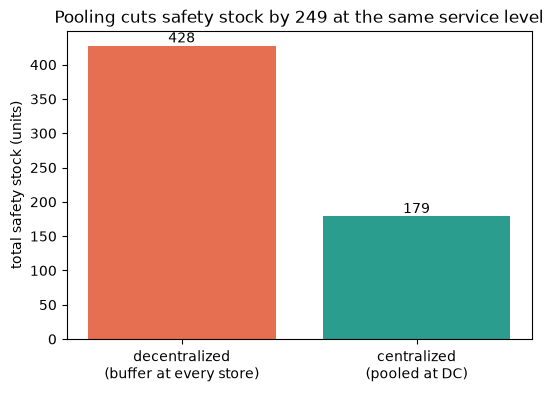

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["decentralized\n(buffer at every store)", "centralized\n(pooled at DC)"],
              [result.decentralized, result.centralized], color=["#e76f51", "#2a9d8f"])
ax.bar_label(bars, fmt="%.0f")
ax.set_ylabel("total safety stock (units)")
ax.set_title(f"Pooling cuts safety stock by {result.savings:.0f} at the same service level")
save_figure(fig, "05_decentralized_vs_centralized")
plt.show()

## The benefit grows with the number of pooled locations

For *N* identical stores the pooled buffer scales as `√N` while the decentralized buffer
scales as `N`, so the ratio shrinks as `1/√N`: the more locations you pool, the larger
the saving.

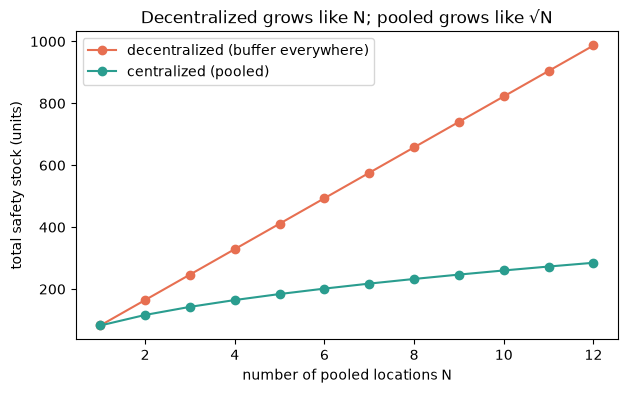

In [4]:
counts = np.arange(1, 13)
sigma_each = 25.0
dec = np.array([decentralized_safety_stock([sigma_each] * n, lead_time, service_level) for n in counts])
cen = np.array([centralized_safety_stock([sigma_each] * n, lead_time, service_level) for n in counts])
factors = np.array([pooling_factor([sigma_each] * n) for n in counts])
save_json({"n_locations": counts, "decentralized": dec, "centralized": cen, "pooling_factor": factors},
          "05_pooling_vs_locations")

fig, ax = plt.subplots()
ax.plot(counts, dec, marker="o", color="#e76f51", label="decentralized (buffer everywhere)")
ax.plot(counts, cen, marker="o", color="#2a9d8f", label="centralized (pooled)")
ax.set_xlabel("number of pooled locations N")
ax.set_ylabel("total safety stock (units)")
ax.set_title("Decentralized grows like N; pooled grows like √N")
ax.legend()
save_figure(fig, "05_pooling_vs_locations")
plt.show()

## Same inventory, higher service

The saving can be taken two ways. Spend the *decentralized* inventory budget on a single
pooled location and the service level rises well above the target — centralizing can
raise service and cut inventory at once.

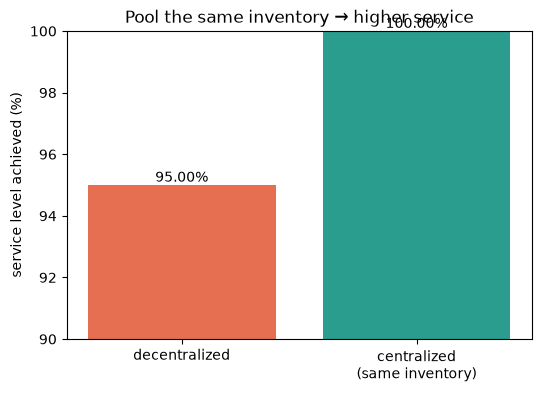

at equal inventory (428 units): decentralized 95.0% -> centralized 99.996%


In [5]:
budget = result.decentralized
z_target = z_score(service_level)
z_central = z_target / result.pooling_factor  # same budget, pooled -> higher z
service_central = float(norm.cdf(z_central))
save_json({"equal_inventory": budget, "decentralized_service": service_level,
           "centralized_service": service_central}, "05_service_at_equal_inventory")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["decentralized", "centralized\n(same inventory)"],
              [service_level * 100, service_central * 100], color=["#e76f51", "#2a9d8f"])
ax.bar_label(bars, fmt="%.2f%%")
ax.set_ylabel("service level achieved (%)")
ax.set_ylim(90, 100)
ax.set_title("Pool the same inventory → higher service")
save_figure(fig, "05_service_at_equal_inventory")
plt.show()
print(f"at equal inventory ({budget:.0f} units): "
      f"decentralized {service_level:.1%} -> centralized {service_central:.3%}")

## Takeaway

Holding a buffer at every node is the intuitive choice and the wrong one. Pooling safety
stock upstream protects the whole network with less total inventory (take the saving as
cash) **or** a higher service level (take it as availability) — because pooled demand is
proportionally less variable. The saving grows with the number of locations pooled.

In [6]:
takeaways = {
    "thesis": "Pooling safety stock upstream protects the network with less total inventory.",
    "decentralized_safety_stock": round(result.decentralized, 1),
    "centralized_safety_stock": round(result.centralized, 1),
    "inventory_saved": round(result.savings, 1),
    "pooling_factor": round(result.pooling_factor, 3),
    "service_at_equal_inventory": round(service_central, 4),
}
save_json(takeaways, "05_takeaways")
takeaways

{'thesis': 'Pooling safety stock upstream protects the network with less total inventory.',
 'decentralized_safety_stock': 427.7,
 'centralized_safety_stock': 178.9,
 'inventory_saved': 248.7,
 'pooling_factor': 0.418,
 'service_at_equal_inventory': 1.0}